# Modelo 1 · Essa mensagem é golpe?

**Desconfie · Global Solution 2026/2 · FIAP 1TDS · Artificial Intelligence & Chatbot**

O cidadão cola uma mensagem de SMS, WhatsApp ou e-mail e o Desconfie responde se ela parece golpe.

| | |
|---|---|
| **Problema** | Classificação binária (golpe = 1, não golpe = 0) |
| **Dados** | `dados/brscamsfacebook.csv`: BrScamsFacebook (golpes reais em pt-BR, Kaggle) + mensagens brasileiras sintéticas geradas aqui |
| **Algoritmos comparados** | TF-IDF + Regressão Logística × TF-IDF + Naive Bayes Multinomial |
| **Métrica principal** | **Recall da classe golpe** — deixar um golpe passar custa mais que um alarme falso |
| **Saída** | `modelos/golpe_texto.joblib`, consumido pela API Flask |

Roteiro: dados → análise exploratória → preparação → treino → avaliação → explicabilidade → exportação.

In [1]:
import sys, json, warnings
from pathlib import Path
from collections import Counter
sys.path.append(str(Path.cwd().parent))   # features.py: o mesmo módulo que a API usa
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_recall_curve,
                             recall_score, precision_score, f1_score, accuracy_score)
from features import limpar_texto

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
AZUL, AMARELO = "#0A2540", "#FFB020"
SEMENTE = 42

## 1. Os dados

Tudo parte do arquivo original `dados/brscamsfacebook.csv` e é tratado aqui mesmo, sem CSV intermediário:

1. **Mascaramento (LGPD):** telefones, CPFs, e-mails e números longos viram `[TELEFONE]`, `[CPF]` e `[EMAIL]`.
2. **BrScamsFacebook:** golpes reais em português do Brasil. As legítimas são a categoria `Seguro`.
3. **Mensagens sintéticas brasileiras:** golpes comuns no Brasil e o mesmo volume de mensagens legítimas,
   para o modelo não aprender que "português do Brasil = golpe".
4. **Junção:** remove duplicadas e embaralha, com semente fixa para o resultado ser sempre o mesmo. A base
   final é salva em `dados/treino_mensagens.csv`.

### 1.1 Mascaramento (LGPD)

In [2]:
import csv, random, re

DADOS = Path("../dados")

RE_EMAIL = re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+")
RE_CPF = re.compile(r"\b\d{3}\.?\d{3}\.?\d{3}-?\d{2}\b")
RE_TEL = re.compile(r"(\+?\d{2,3}\s?)?(\(?\d{2}\)?\s?)?\b\d{4,5}[-\s]?\d{4}\b|\b8[2-7]\d{7}\b")


def mascarar(texto):
    texto = RE_EMAIL.sub("[EMAIL]", texto)
    texto = RE_CPF.sub("[CPF]", texto)
    texto = RE_TEL.sub("[TELEFONE]", texto)
    texto = re.sub(r"(?<!\d)\+?\d{9,}(?!\d)", "[TELEFONE]", texto)  # números longos, mesmo colados em letras
    return re.sub(r"\s+", " ", texto).strip()

### 1.2 BrScamsFacebook (golpes reais)

A categoria "Golpes de Desinformação Digital" fica de fora: é fake news, não golpe que pede dinheiro ou dados.

In [3]:
CATEGORIAS_BRSCAMS = {
    "Golpes Baseados Em Relacionamento": (1, "relacionamento"),
    "Golpes de Ganho Financeiro Ilusório": (1, "ganho_ilusorio"),
    "Ataques de Phishing e Roubo de Dados": (1, "phishing"),
    "Fraudes em Lojas Virtuais Falsas": (1, "loja_falsa"),
    "Seguro": (0, "legitima"),
}


def ler_brscams():
    linhas = []
    with open(DADOS / "brscamsfacebook.csv", encoding="utf-8") as f:
        for r in csv.DictReader(f):
            if r["Categoria"] not in CATEGORIAS_BRSCAMS:
                continue
            golpe, tipo = CATEGORIAS_BRSCAMS[r["Categoria"]]
            fonte = r["Dataset"].lower().replace(" ", "")  # "Externo 4" -> "externo4"
            linhas.append({"texto": mascarar(r["Mensagem"]), "golpe": golpe, "tipo": tipo,
                           "origem": "brscams_" + fonte, "pais": "BR"})
    return linhas

### 1.3 Mensagens sintéticas brasileiras

8 tipos de golpe × 35 e 8 tipos de mensagem legítima × 35, montados a partir de modelos de frase.

In [4]:
BANCOS = [("Itaú", "itau"), ("Bradesco", "bradesco"), ("Caixa", "caixa"), ("Banco do Brasil", "bb"),
          ("Nubank", "nubank"), ("Santander", "santander"), ("Inter", "inter"), ("C6 Bank", "c6")]
LOJAS = ["Magazine", "Casas Bahia", "Americanas", "Mercado Livre", "Shopee", "Amazon"]
NOMES = ["Ana", "Bruno", "Carla", "Diego", "Eduarda", "Felipe", "Gabriela", "Henrique", "Isabela",
         "João", "Larissa", "Marcos", "Natália", "Otávio", "Paula", "Rafael", "Sabrina", "Thiago"]
PARENTES = ["mãe", "pai", "vó", "tia", "mana", "amor"]
TLDS = ["xyz", "top", "online", "site", "info", "com", "net", "click"]
PALAVRAS_LINK = ["seguranca", "atualiza", "regulariza", "desbloqueio", "cliente", "app", "valida", "suporte"]
ENCURTADORES = ["bit.ly", "tinyurl.com", "cutt.ly", "is.gd"]


def valor():
    reais = random.choice(["89", "127", "249", "389", "499", "890", "1.250", "1.890", "2.400", "3.200", "4.750"])
    return f"R$ {reais}" + random.choice([",00", ",90", ",50"])


def link_falso(slug=None):
    if random.random() < 0.3:
        cod = "".join(random.choices("abcdefghijkmnpqrstuvwxyz23456789", k=6))
        return f"{random.choice(ENCURTADORES)}/{cod}"
    slug = slug or random.choice([b[1] for b in BANCOS] + ["correios", "gov", "receita", "pix"])
    sep = random.choice(["-", ""])
    dominio = f"{slug}{sep}{random.choice(PALAVRAS_LINK)}.{random.choice(TLDS)}"
    return random.choice(["https://", "http://", ""]) + dominio + random.choice(["", "/login", "/acesso", "/pix"])


def tel():
    return f"(11) 9{random.randint(1000, 9999)}-{random.randint(1000, 9999)}"


def hora():
    return f"{random.randint(8, 20)}h"


def prazo():
    return random.choice(["30 minutos", "2 horas", "hoje", "até as 23h59", "24 horas"])


# ---------------------------------------------------------------- golpes brasileiros (golpe = 1)
def g_falsa_central():
    b, s = random.choice(BANCOS)
    return random.choice([
        f"{b}: identificamos uma compra de {valor()} no seu cartão. Se não reconhece, ligue agora {tel()} para cancelar.",
        f"URGENTE {b}: seu PIX de {valor()} foi bloqueado por suspeita de fraude. Regularize em {prazo()}: {link_falso(s)}",
        f"Prezado cliente {b}, sua conta será suspensa {prazo()}. Atualize seus dados e senha em {link_falso(s)}",
        f"{b} informa: seu token expirou. Para não ter o acesso bloqueado, valide em {link_falso(s)} informando CPF e senha.",
        f"Aqui é da central de segurança do {b}. Detectamos acesso suspeito. Responda com o código que enviamos por SMS para cancelar.",
        f"Alerta {b}: transferência de {valor()} pendente de autorização. Caso não tenha sido você, acesse {link_falso(s)} imediatamente.",
        f"{b}: seu cartão foi clonado. Um atendente vai te ligar, confirme os números do cartão e a senha para o estorno.",
    ])


def g_falso_parente():
    p, n = random.choice(PARENTES), random.choice(NOMES)
    return random.choice([
        f"Oi {p}, troquei de número, salva esse. Tô sem acesso ao app do banco, consegue fazer um pix de {valor()} pra mim? Te devolvo amanhã.",
        f"{p.capitalize()}, é o {n}. Meu celular quebrou, esse é meu número novo. Preciso pagar uma conta urgente, me ajuda?",
        f"Oi {p}! Número novo aqui. Tenho que pagar um boleto hoje e o meu limite estourou. Pode mandar {valor()} nessa chave pix?",
        f"{p}, não conta pra ninguém, tô num aperto. Faz um pix de {valor()} pro meu amigo {n}, depois te explico.",
        f"Salva meu novo contato {p}. Tá dando erro no meu banco, me empresta {valor()} só até sexta?",
    ])


def g_boleto():
    return random.choice([
        f"Sua fatura de {random.choice(['energia', 'internet', 'condomínio', 'cartão'])} venceu. Evite o corte: pague a segunda via com desconto em {link_falso()}",
        f"Débito pendente em seu CPF no valor de {valor()}. Quite {prazo()} para evitar protesto: {link_falso('receita')}",
        f"Aviso de cobrança: boleto em atraso. Gere a 2ª via atualizada em {link_falso()} e evite negativação no Serasa.",
        f"Negocie sua dívida com 90% de desconto só {prazo()}! Acesse {link_falso()} e pague com boleto.",
    ])


def g_falsa_entrega():
    cod = f"BR{random.randint(10000000, 99999999)}BR"
    return random.choice([
        f"Correios: sua encomenda {cod} está retida. Pague a taxa de importação de {valor()} em {link_falso('correios')}",
        f"Sua entrega não pôde ser realizada por endereço incompleto. Atualize em {link_falso('correios')} em até {prazo()}.",
        f"Encomenda {cod} aguardando pagamento de taxa alfandegária. Após {prazo()} será devolvida ao remetente: {link_falso()}",
        f"Tentamos entregar seu pedido hoje. Reagende pelo link {link_falso()} e confirme o pagamento do frete de {valor()}.",
    ])


def g_falso_emprego():
    return random.choice([
        f"Olá! Vaga de meio período em casa, ganhe {valor()} por dia curtindo vídeos. Chama no WhatsApp {tel()}",
        f"Você foi selecionado para trabalho remoto. Ganhos de até {valor()} por dia. Para começar, pague a taxa de cadastro.",
        f"Oportunidade: avaliar produtos online, renda extra de {valor()} por semana. Fale com a recrutadora {random.choice(NOMES)} pelo link {link_falso()}",
        f"Vaga temporária com salário de {valor()}. Envie CPF e foto do documento para garantir sua vaga {prazo()}.",
    ])


def g_premio():
    return random.choice([
        f"Parabéns! Seu número foi sorteado e você ganhou {valor()}. Resgate em {link_falso()} {prazo()}.",
        f"Você ganhou um iPhone na promoção de aniversário da {random.choice(LOJAS)}! Pague só o frete em {link_falso()}",
        f"Seu CPF tem valores a receber do governo: {valor()}. Consulte e resgate em {link_falso('gov')}",
        f"Pontos do seu cartão expiram {prazo()}! Troque por {valor()} em dinheiro em {link_falso()}",
        f"Parabéns, cliente premiado! Para liberar seu prêmio de {valor()}, faça um pix de {valor()} de taxa.",
    ])


def g_loja_falsa():
    lj = random.choice(LOJAS)
    return random.choice([
        f"Queima de estoque {lj}: Air fryer por {valor()} só {prazo()}! Compre via pix em {link_falso()}",
        f"{lj} liquidação: tudo com 80% OFF. Últimas unidades, aproveite: {link_falso()}",
        f"Seu carrinho na {lj} tem um cupom de 70% esperando. Finalize {prazo()} no link {link_falso()}",
        f"Black Friday antecipada! TV 55 polegadas por {valor()}. Pagamento só no pix: {link_falso()}",
    ])


def g_pix_falso():
    n = random.choice(NOMES)
    return random.choice([
        f"Oi, fiz um pix de {valor()} pra você por engano. Pode devolver pra essa chave? Segue o comprovante.",
        f"Seu PIX agendado de {valor()} para {n} será processado {prazo()}. Para cancelar acesse {link_falso('pix')}",
        f"Você recebeu um PIX de {valor()}. Para liberar o valor, confirme seus dados em {link_falso('pix')}",
        f"Comprovante: transferi {valor()} a mais. Me devolve a diferença nesse pix por favor, é urgente.",
    ])


GOLPES = {"falsa_central": g_falsa_central, "falso_parente": g_falso_parente, "boleto_falso": g_boleto,
          "falsa_entrega": g_falsa_entrega, "falso_emprego": g_falso_emprego, "premio": g_premio,
          "loja_falsa": g_loja_falsa, "pix_falso": g_pix_falso}


# ---------------------------------------------------------------- mensagens legítimas brasileiras (golpe = 0)
def l_banco():
    b, _ = random.choice(BANCOS)
    return random.choice([
        f"{b}: compra aprovada de {valor()} em {random.choice(LOJAS)} no cartão final {random.randint(1000, 9999)}.",
        f"Você recebeu um PIX de {valor()} de {random.choice(NOMES)}. Confira no app {b}.",
        f"{b}: seu código de verificação é {random.randint(100000, 999999)}. Não compartilhe com ninguém, nem com funcionários do banco.",
        f"{b}: a fatura do seu cartão fecha dia {random.randint(1, 28)}. Valor parcial {valor()}. Veja os detalhes no app.",
        f"{b} lembra: nunca pedimos senha, token ou código por SMS, WhatsApp ou ligação.",
    ])


def l_entrega():
    cod = f"BR{random.randint(10000000, 99999999)}BR"
    return random.choice([
        f"Seu pedido da {random.choice(LOJAS)} saiu para entrega e chega hoje até as {hora()}. Acompanhe pelo app.",
        f"Correios: objeto {cod} entregue em {random.randint(1, 28)}/{random.randint(1, 12)} às {hora()}.",
        f"{random.choice(LOJAS)}: pedido confirmado! Previsão de entrega em {random.randint(2, 9)} dias úteis.",
        f"Seu pacote está no centro de distribuição da sua cidade. Acompanhe pelo app da {random.choice(LOJAS)}.",
    ])


def l_cobranca():
    return random.choice([
        f"Sua conta de {random.choice(['energia', 'água', 'internet', 'celular'])} de {random.choice(['outubro', 'novembro'])} está disponível no app. Vencimento dia {random.randint(1, 28)}.",
        f"Lembrete: a mensalidade da escola vence dia {random.randint(1, 28)}. O boleto está no portal do aluno.",
        f"Recebemos o pagamento de {valor()}. Obrigado!",
        f"Débito automático programado de {valor()} para o dia {random.randint(1, 28)}.",
    ])


def l_saude():
    return random.choice([
        f"Lembrete: sua consulta com Dr(a). {random.choice(NOMES)} é amanhã às {hora()}. Responda 1 para confirmar ou 2 para remarcar.",
        f"Seu resultado de exame está disponível no site do laboratório. Use o protocolo entregue no atendimento.",
        f"Farmácia: seu pedido está pronto para retirada até as {hora()}.",
        f"Campanha de vacinação: postos abertos sábado das 8h às 17h. Leve documento e carteira de vacinação.",
    ])


def l_conversa():
    n = random.choice(NOMES)
    return random.choice([
        f"Oi {random.choice(PARENTES)}, chego aí umas {hora()}. Quer que eu leve pão?",
        f"{n}, a reunião mudou pra {hora()}, mesma sala.",
        f"Bom dia! Vai ter almoço de domingo aí? Avisa que eu levo a sobremesa.",
        f"Te mandei o pix da pizza, confere aí. Valeu!",
        f"Mãe, cheguei bem. Amanhã te ligo.",
        f"Alguém sabe se a aula de amanhã vai ser online?",
    ])


def l_servico():
    return random.choice([
        f"Seu código de acesso ao WhatsApp é {random.randint(100, 999)}-{random.randint(100, 999)}. Não compartilhe este código.",
        f"Sua corrida foi concluída. Total {valor()}. Avalie seu motorista no app.",
        f"Operadora: seu pacote de dados foi renovado. Consulte o saldo no app.",
        f"Seu agendamento no salão está confirmado para sexta às {hora()}.",
    ])


def l_governo():
    return random.choice([
        f"Gov.br: seu login foi feito em um novo dispositivo. Se não foi você, troque a senha pelo app gov.br.",
        f"Prefeitura: o IPTU está disponível para consulta no site oficial da prefeitura. Pagamento em cota única até dia {random.randint(1, 28)}.",
        f"Detran: seu agendamento para renovação da CNH está confirmado para {random.randint(1, 28)}/{random.randint(1, 12)} às {hora()}.",
        f"Defesa Civil: previsão de chuva forte nas próximas horas. Em emergência, ligue 199.",
    ])


def l_compra():
    lj = random.choice(LOJAS)
    return random.choice([
        f"{lj}: seu pagamento de {valor()} foi aprovado. Obrigado pela compra!",
        f"{lj}: a nota fiscal do seu pedido está disponível em Meus Pedidos no app.",
        f"Você tem um cupom de 10% para a próxima compra no app da {lj}. Válido até o fim do mês.",
        f"{lj}: seu estorno de {valor()} foi processado e aparece na próxima fatura.",
    ])


LEGITIMAS = {"banco_aviso": l_banco, "entrega": l_entrega, "cobranca": l_cobranca, "saude": l_saude,
             "conversa": l_conversa, "servico": l_servico, "governo": l_governo, "compra": l_compra}


def gerar(funcoes, golpe, por_tipo):
    linhas, vistos = [], set()
    for tipo, f in funcoes.items():
        n, tentativas = 0, 0
        while n < por_tipo and tentativas < por_tipo * 50:
            tentativas += 1
            t = mascarar(f())
            if t not in vistos:
                vistos.add(t)
                linhas.append({"texto": t, "golpe": golpe, "tipo": tipo, "origem": "sintetico", "pais": "BR"})
                n += 1
    return linhas

### 1.4 Juntando tudo

In [5]:
random.seed(SEMENTE)
linhas = ler_brscams() + gerar(GOLPES, 1, 35) + gerar(LEGITIMAS, 0, 35)
unicas, vistos = [], set()
for l in linhas:
    if l["texto"] and l["texto"].lower() not in vistos:
        vistos.add(l["texto"].lower())
        unicas.append(l)
random.shuffle(unicas)

df = pd.DataFrame(unicas, columns=["texto", "golpe", "tipo", "origem", "pais"])
df.to_csv("../dados/treino_mensagens.csv", index=False)   # a base final usada no treino
df["golpe"] = df["golpe"].astype(int)
df["texto_limpo"] = df["texto"].map(limpar_texto)   # mesma limpeza que o modelo aplica

print(df.shape, "| nulos:", int(df.isna().sum().sum()), "| textos duplicados:", df["texto"].duplicated().sum())
display(pd.crosstab(df["origem"], df["golpe"].map({0: "não golpe", 1: "golpe"}), margins=True))
df[["texto", "texto_limpo", "golpe", "tipo", "origem"]].head(3)

(933, 6) | nulos: 0 | textos duplicados: 0


golpe,golpe,não golpe,All
origem,,,
brscams_externo1,65,0,65
brscams_externo2,56,21,77
brscams_externo3,0,34,34
brscams_externo4,36,0,36
brscams_externo5,25,0,25
brscams_externo6,31,12,43
brscams_externo7,36,0,36
brscams_interno,49,8,57
sintetico,280,280,560


,texto,texto_limpo,golpe,tipo,origem
0,"Prezado cliente Caixa, sua conta será suspensa...","prezado cliente caixa, sua conta sera suspensa...",1,falsa_central,sintetico
1,Sua fatura de internet venceu. Evite o corte: ...,sua fatura de internet venceu. evite o corte: ...,1,boleto_falso,sintetico
2,Os números Voda de hoje que terminam em 7548 s...,os numeros voda de hoje que terminam em tokenn...,1,phishing,brscams_externo2


**Limpeza (`features.limpar_texto`):** minúsculas, sem acento, links viram `tokenurl`, números viram
`tokennum`, e dados mascarados viram `tokentelefone`, `tokencpf`, `tokenemail`. Usar a mesma função aqui
e na API garante que o modelo veja em produção exatamente o que viu no treino.

## 2. Análise exploratória

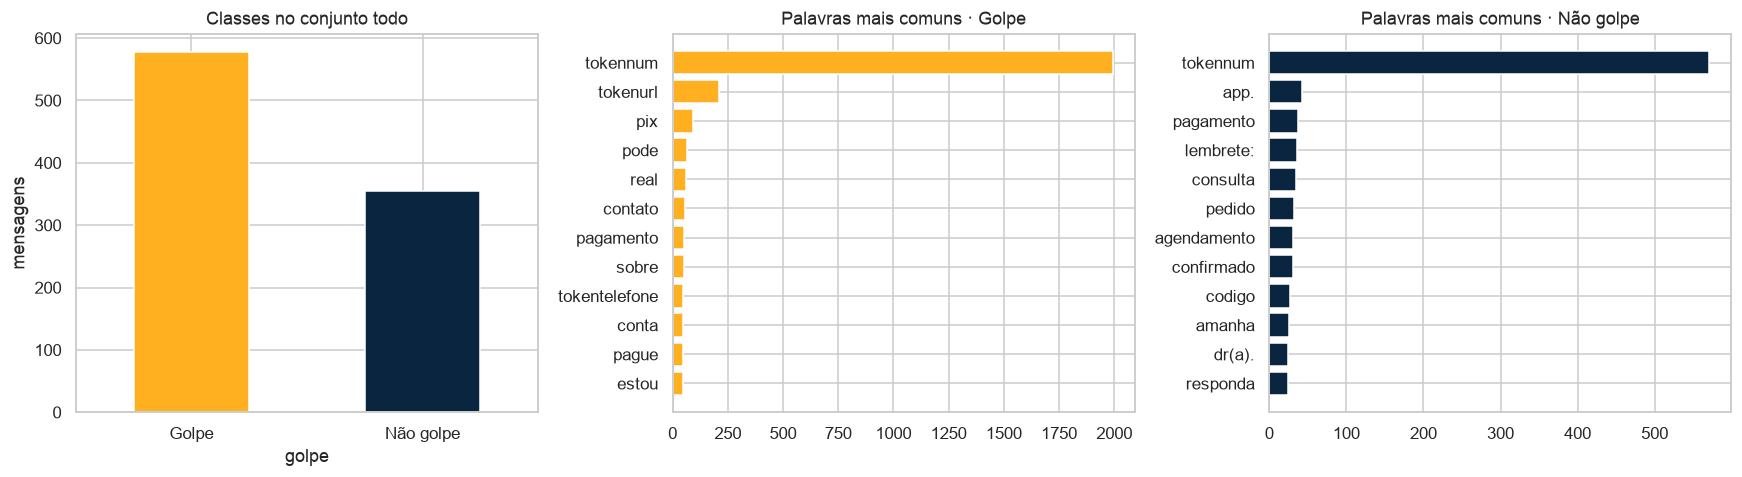

golpe
1    0.62
0    0.38


In [6]:
STOP = set(("a o e de da do das dos em no na nos nas um uma para pra por com que se seu sua te me meu minha "
            "eu voce vc tu ja ate as os ao aos isso esse essa este esta foi ser ter tem nao sim mais muito ou mas como "
            "la ai aqui so ok ola boa bom dia tarde noite").split())

def top_palavras(textos, n=12):
    c = Counter(p for t in textos for p in t.split() if p not in STOP and len(p) > 2)
    return pd.DataFrame(c.most_common(n), columns=["palavra", "freq"]).iloc[::-1]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
df["golpe"].map({0: "Não golpe", 1: "Golpe"}).value_counts().plot.bar(ax=ax[0], color=[AMARELO, AZUL], rot=0)
ax[0].set_title("Classes no conjunto todo"); ax[0].set_ylabel("mensagens")
for a, (g, nome, cor) in zip(ax[1:], [(1, "Golpe", AMARELO), (0, "Não golpe", AZUL)]):
    t = top_palavras(df[df["golpe"] == g]["texto_limpo"])
    a.barh(t["palavra"], t["freq"], color=cor); a.set_title(f"Palavras mais comuns · {nome}")
plt.tight_layout(); plt.show()

print(df["golpe"].value_counts(normalize=True).round(3).to_string())

**O que vemos:** as classes estão **desbalanceadas** (~62% golpe), então acurácia sozinha engana — um modelo
que dissesse "golpe" para tudo acertaria ~80% no teste real. Olhamos recall, precisão e F1, e usamos
`class_weight="balanced"`.

Nas palavras, os golpes trazem **pedido de dinheiro e troca de canal** (`valor`, `manda`, `numero`, `conta`,
`pix`, `tokentelefone`, `tokenurl`); as legítimas trazem conversa e confirmação. Isso justifica TF-IDF:
o que separa as classes são as palavras, não o tamanho da mensagem.

As sintéticas foram criadas **balanceadas** de propósito (280 golpes / 280 legítimas): se só os golpes fossem
brasileiros, o modelo aprenderia "português do Brasil = golpe" em vez dos sinais de golpe.

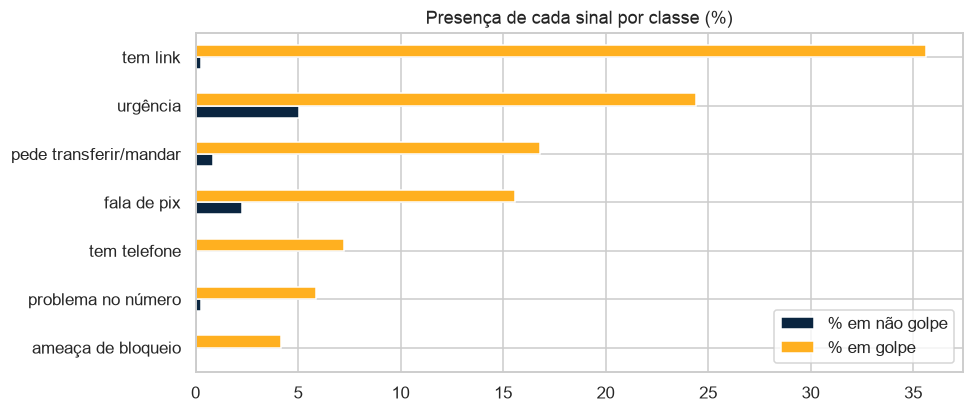

,% em não golpe,% em golpe
tem link,0.3,35.6
urgência,5.1,24.4
pede transferir/mandar,0.8,16.8
fala de pix,2.3,15.6
tem telefone,0.0,7.3
problema no número,0.3,5.9
ameaça de bloqueio,0.0,4.2


In [7]:
sinais = {
    "tem link":                df["texto_limpo"].str.contains("tokenurl"),
    "tem telefone":            df["texto_limpo"].str.contains("tokentelefone"),
    "fala de pix":             df["texto_limpo"].str.contains(r"\bpix\b"),
    "pede transferir/mandar":  df["texto_limpo"].str.contains(r"transfer|mand[ae]|envi[ae]"),
    "urgência":                df["texto_limpo"].str.contains(r"urgente|agora|imediat|hoje|prazo|expira"),
    "ameaça de bloqueio":      df["texto_limpo"].str.contains(r"bloque|suspens|cancelad"),
    "problema no número":      df["texto_limpo"].str.contains(r"problema|troquei|numero novo|novo numero"),
}
tab = pd.DataFrame({k: v.groupby(df["golpe"]).mean() for k, v in sinais.items()}).T * 100
tab.columns = ["% em não golpe", "% em golpe"]
tab = tab.sort_values("% em golpe")
tab.plot.barh(figsize=(9, 4), color=[AZUL, AMARELO])
plt.title("Presença de cada sinal por classe (%)"); plt.show()
tab.round(1).sort_values("% em golpe", ascending=False)

**O que vemos:** os sinais do motor de regras do Desconfie aparecem muito mais nos golpes — link em 36% dos
golpes contra 0,3% das legítimas, urgência 24% × 5%, pedido de transferência 17% × 1%. Mas **nenhum resolve
sozinho**: "mandar" e "pix" também aparecem em conversa normal ("te mandei o pix da pizza"). Por isso o
Desconfie combina **regras** (explicáveis) com o **modelo** (que pesa todas as palavras juntas).

## 3. Preparação

Decisão importante: **o teste usa só mensagens reais.** Testar com as sintéticas avaliaria o modelo em frases
parecidas com as do treino e inflaria as métricas.

- **Teste:** 25% das mensagens reais (BrScamsFacebook), estratificado pela classe.
- **Treino:** o resto das reais + 80% das sintéticas brasileiras.
- **Teste BR:** os 20% restantes das sintéticas, só como checagem ilustrativa.

In [8]:
reais = df[df["origem"].str.startswith("brscams")]
sint  = df[df["origem"] == "sintetico"]

reais_treino, teste    = train_test_split(reais, test_size=0.25, stratify=reais["golpe"], random_state=SEMENTE)
sint_treino, teste_br  = train_test_split(sint,  test_size=0.20, stratify=sint["golpe"],  random_state=SEMENTE)
treino = pd.concat([reais_treino, sint_treino]).sample(frac=1, random_state=SEMENTE)

X_treino, y_treino = treino["texto"], treino["golpe"]
X_teste,  y_teste  = teste["texto"],  teste["golpe"]

pd.DataFrame({"linhas": [len(treino), len(teste), len(teste_br)],
              "% golpe": [y_treino.mean(), y_teste.mean(), teste_br["golpe"].mean()]},
             index=["treino", "teste (reais)", "teste BR (sintético)"]).round(3)

,linhas,% golpe
treino,727,0.615
teste (reais),94,0.798
teste BR (sintético),112,0.500


## 4. Treinamento

Dois modelos, cada um num `Pipeline` que recebe **o texto cru** — assim a API só chama
`predict_proba(["mensagem"])` e não precisa repetir nenhum pré-processamento.

- **TF-IDF:** cada palavra e cada par de palavras vira uma coluna, com peso maior para termos frequentes na
  mensagem e raros no conjunto.
- **Regressão Logística:** um peso por termo. Rápida e **explicável**.
- **Naive Bayes Multinomial:** clássico para texto, serve de comparação.

Comparação por **validação cruzada estratificada de 5 partes** no treino.

In [9]:
def tfidf():
    return TfidfVectorizer(preprocessor=limpar_texto, ngram_range=(1, 2), min_df=2, sublinear_tf=True)

modelos = {
    "Regressão Logística": Pipeline([("tfidf", tfidf()),
                                     ("clf", LogisticRegression(class_weight="balanced", C=5, max_iter=2000))]),
    "Naive Bayes":         Pipeline([("tfidf", tfidf()), ("clf", MultinomialNB(alpha=0.3))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
pd.DataFrame([
    {"modelo": nome, **{k.replace("test_", ""): f"{v.mean():.3f} ± {v.std():.3f}"
                        for k, v in cross_validate(m, X_treino, y_treino, cv=cv,
                                                   scoring=["recall", "precision", "f1", "roc_auc"]).items()
                        if k.startswith("test_")}}
    for nome, m in modelos.items()]).set_index("modelo")

,recall,precision,f1,roc_auc
modelo,,,,
Regressão Logística,0.991 ± 0.008,0.913 ± 0.030,0.950 ± 0.015,0.981 ± 0.010
Naive Bayes,0.993 ± 0.005,0.900 ± 0.027,0.944 ± 0.014,0.984 ± 0.009


## 5. Avaliação no teste (só mensagens reais)

In [10]:
def metricas(y, p, lim=0.5):
    pred = (p >= lim).astype(int)
    return {"recall (golpe)": recall_score(y, pred), "precisão (golpe)": precision_score(y, pred),
            "F1": f1_score(y, pred), "acurácia": accuracy_score(y, pred), "ROC AUC": roc_auc_score(y, p)}

probs = {}
for nome, m in modelos.items():
    m.fit(X_treino, y_treino)
    probs[nome] = m.predict_proba(X_teste)[:, 1]

comparacao = pd.DataFrame([{"modelo": n, **metricas(y_teste, p)} for n, p in probs.items()]).set_index("modelo").round(3)
for nome, p in probs.items():
    print(f"=== {nome} ===")
    print(classification_report(y_teste, (p >= 0.5).astype(int), target_names=["Não golpe", "Golpe"], digits=3))
comparacao

=== Regressão Logística ===
              precision    recall  f1-score   support

   Não golpe      1.000     0.421     0.593        19
       Golpe      0.872     1.000     0.932        75

    accuracy                          0.883        94
   macro avg      0.936     0.711     0.762        94
weighted avg      0.898     0.883     0.863        94

=== Naive Bayes ===
              precision    recall  f1-score   support

   Não golpe      0.667     0.211     0.320        19
       Golpe      0.830     0.973     0.896        75

    accuracy                          0.819        94
   macro avg      0.748     0.592     0.608        94
weighted avg      0.797     0.819     0.779        94



,recall (golpe),precisão (golpe),F1,acurácia,ROC AUC
modelo,,,,,
Regressão Logística,1.000,0.872,0.932,0.883,0.899
Naive Bayes,0.973,0.830,0.896,0.819,0.906


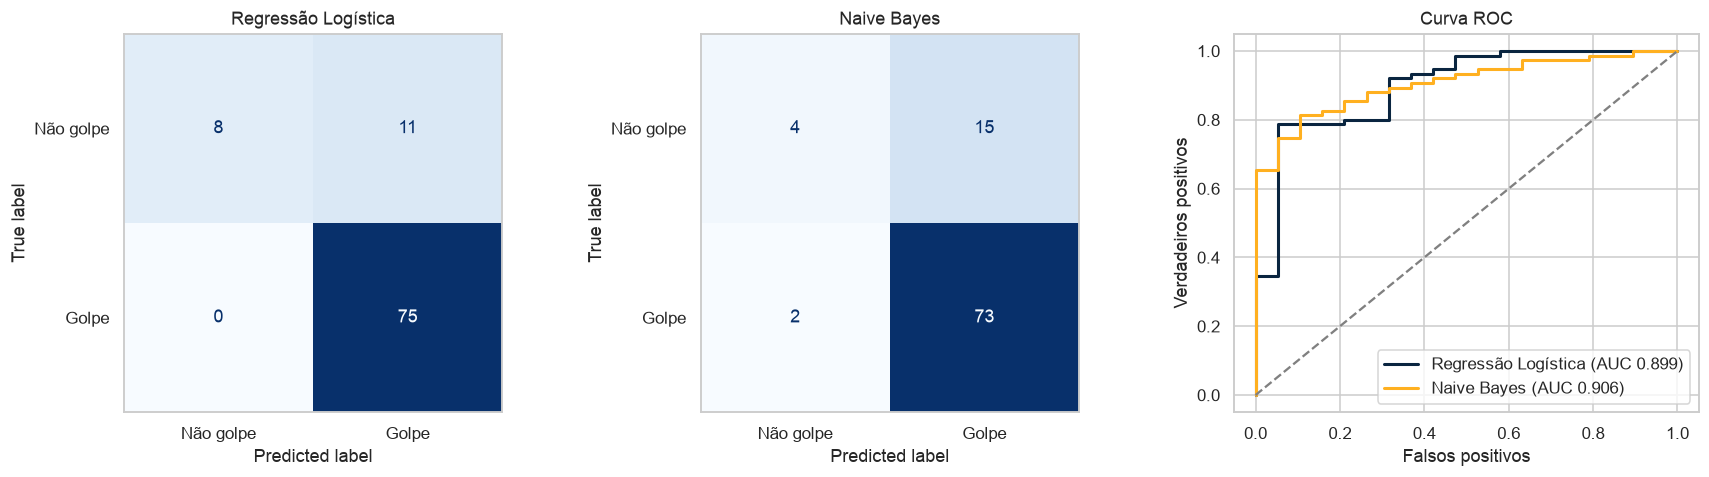

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (nome, p) in zip(ax, probs.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_teste, (p >= 0.5).astype(int)),
                           display_labels=["Não golpe", "Golpe"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(nome); a.grid(False)
for (nome, p), cor in zip(probs.items(), [AZUL, AMARELO]):
    fpr, tpr, _ = roc_curve(y_teste, p)
    ax[2].plot(fpr, tpr, color=cor, lw=2, label=f"{nome} (AUC {roc_auc_score(y_teste, p):.3f})")
ax[2].plot([0, 1], [0, 1], "--", color="grey")
ax[2].set(title="Curva ROC", xlabel="Falsos positivos", ylabel="Verdadeiros positivos"); ax[2].legend(loc="lower right")
plt.tight_layout(); plt.show()

### 5.1 Modelo e limiar escolhidos

O modelo é o de **maior recall + F1**. Em cima dele escolhemos o **limiar**: o menor corte que garante
**recall ≥ 90%** com a maior precisão possível. Esse valor vai no `.json` ao lado do modelo, e é a API que
o aplica — o `.joblib` devolve só a probabilidade.

Modelo escolhido: Regressão Logística
Limiar: 0.655 → recall 0.920, precisão 0.920


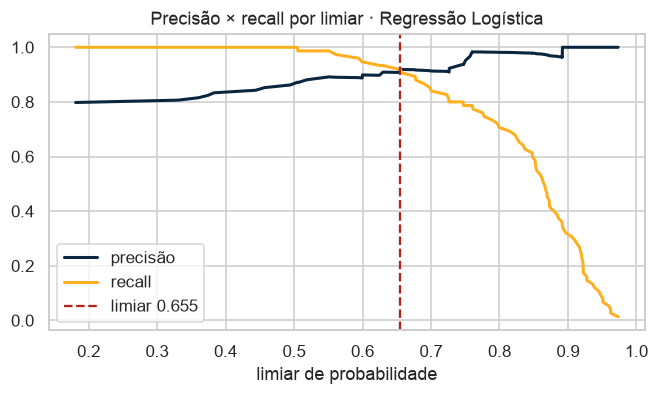

Checagem nas sintéticas BR (otimista, não é a métrica oficial):
              precision    recall  f1-score   support

   Não golpe      1.000     0.946     0.972        56
       Golpe      0.949     1.000     0.974        56

    accuracy                          0.973       112
   macro avg      0.975     0.973     0.973       112
weighted avg      0.975     0.973     0.973       112



In [12]:
escolhido = comparacao["recall (golpe)"].add(comparacao["F1"]).idxmax()
modelo, p = modelos[escolhido], probs[escolhido]

prec, rec, lim = precision_recall_curve(y_teste, p)
limiar, prec_l, rec_l = max([(l, pr, r) for pr, r, l in zip(prec[:-1], rec[:-1], lim) if r >= 0.90],
                            key=lambda x: x[1])
print(f"Modelo escolhido: {escolhido}")
print(f"Limiar: {limiar:.3f} → recall {rec_l:.3f}, precisão {prec_l:.3f}")

plt.figure(figsize=(7, 3.5))
plt.plot(lim, prec[:-1], label="precisão", color=AZUL, lw=2)
plt.plot(lim, rec[:-1], label="recall", color=AMARELO, lw=2)
plt.axvline(limiar, ls="--", color="#B42318", label=f"limiar {limiar:.3f}")
plt.xlabel("limiar de probabilidade"); plt.title(f"Precisão × recall por limiar · {escolhido}")
plt.legend(); plt.show()

print("Checagem nas sintéticas BR (otimista, não é a métrica oficial):")
print(classification_report(teste_br["golpe"], (modelo.predict_proba(teste_br["texto"])[:, 1] >= limiar).astype(int),
                            target_names=["Não golpe", "Golpe"], digits=3))

## 6. Explicabilidade

Cada termo tem um peso na Regressão Logística: positivo puxa para "golpe", negativo para "não golpe". A API
usa exatamente esses pesos (`tfidf × coef_`) para montar o campo `termosMaisRelevantes` que o cidadão vê.

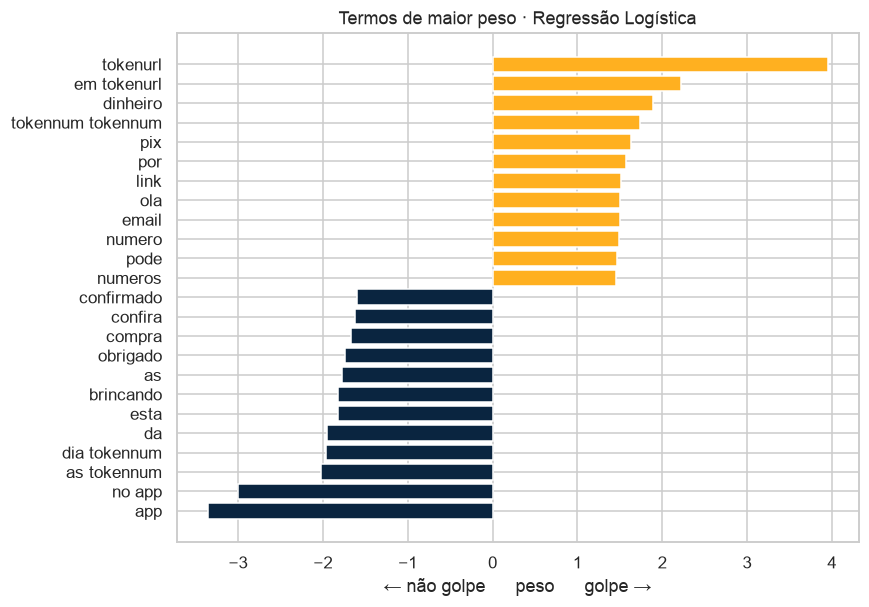

In [13]:
if hasattr(modelo.named_steps["clf"], "coef_"):
    termos = modelo.named_steps["tfidf"].get_feature_names_out()
    pesos  = modelo.named_steps["clf"].coef_[0]
    ordem  = np.argsort(pesos)
    top = pd.DataFrame({"termo": np.r_[termos[ordem[:12]], termos[ordem[-12:]]],
                        "peso":  np.r_[pesos[ordem[:12]],  pesos[ordem[-12:]]]}).sort_values("peso")
    plt.figure(figsize=(8, 6))
    plt.barh(top["termo"], top["peso"], color=np.where(top["peso"] > 0, AMARELO, AZUL))
    plt.title(f"Termos de maior peso · {escolhido}")
    plt.xlabel("← não golpe      peso      golpe →"); plt.show()

## 7. Onde o modelo erra, e como vai em mensagens novas

In [14]:
erros = teste.assign(prob=p, pred=(p >= limiar).astype(int))
print("Golpes que passaram (falsos negativos):")
print(erros.query("golpe == 1 and pred == 0").nsmallest(5, "prob")[["texto", "prob"]].to_string(), "\n")
print("Alarmes falsos (falsos positivos):")
print(erros.query("golpe == 0 and pred == 1").nlargest(5, "prob")[["texto", "prob"]].to_string())

Golpes que passaram (falsos negativos):
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               texto      prob
155                                                                                                                                                                                                                                                                                                                                                                                                                                              

**O que vemos:** boa parte dos erros são mensagens legítimas que **parecem anúncio ou promoção**, escritas do
mesmo jeito que o golpe. Só o texto não separa isso — o contexto (quem mandou, se é número conhecido) faria.
Por isso o Desconfie mostra **"suspeito"** em vez de cravar golpe quando a nota fica no meio.

In [15]:
exemplos = [
    "URGENTE: seu PIX de R$ 890,00 foi bloqueado. Regularize em 30 minutos: https://itau-seguranca.xyz/login",
    "Oi mãe, troquei de número. Consegue fazer um pix de 1.500 pra mim agora? Te devolvo amanhã",
    "Correios: sua encomenda está retida. Pague a taxa de R$ 49,90 em correios-taxa.top",
    "Seu pedido saiu para entrega e chega hoje até as 18h. Acompanhe pelo app.",
    "Bradesco: seu código de verificação é 482913. Não compartilhe com ninguém.",
    "Amanhã chego umas 19h, quer que eu leve pão?",
]
pe = modelo.predict_proba(exemplos)[:, 1]
pd.DataFrame({"mensagem": exemplos, "prob. golpe": pe.round(3),
              "acima do limiar?": np.where(pe >= limiar, "SIM", "não")})

,mensagem,prob. golpe,acima do limiar?
0,"URGENTE: seu PIX de R$ 890,00 foi bloqueado. R...",0.890,SIM
1,"Oi mãe, troquei de número. Consegue fazer um p...",0.905,SIM
2,Correios: sua encomenda está retida. Pague a t...,0.936,SIM
3,Seu pedido saiu para entrega e chega hoje até ...,0.053,não
4,Bradesco: seu código de verificação é 482913. ...,0.096,não
5,"Amanhã chego umas 19h, quer que eu leve pão?",0.072,não


## 8. Exportação

O modelo escolhido é retreinado com **todos os dados** (treino + teste) para aproveitar o máximo de exemplos,
e salvo em `.joblib`. O limiar e as métricas vão num `.json` ao lado — a API lê os dois.

In [16]:
clf = modelo.named_steps["clf"]
final = Pipeline([("tfidf", tfidf()), ("clf", clf.__class__(**clf.get_params()))]).fit(df["texto"], df["golpe"])

Path("../modelos").mkdir(exist_ok=True)
joblib.dump(final, "../modelos/golpe_texto.joblib")
meta = {"modelo": escolhido, "limiar": round(float(limiar), 3),
        "metricas_teste_real": comparacao.loc[escolhido].to_dict(),
        "linhas_treino_final": int(len(df))}
Path("../modelos/golpe_texto.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2))
print(json.dumps(meta, ensure_ascii=False, indent=2))

# confere que o arquivo salvo carrega e responde
carregado = joblib.load("../modelos/golpe_texto.joblib")
print("teste de carga:", carregado.predict_proba(["Parabéns! Você ganhou R$ 5.000. Resgate em premio-gov.xyz"])[0, 1].round(3))

{
  "modelo": "Regressão Logística",
  "limiar": 0.655,
  "metricas_teste_real": {
    "recall (golpe)": 1.0,
    "precisão (golpe)": 0.872,
    "F1": 0.932,
    "acurácia": 0.883,
    "ROC AUC": 0.899
  },
  "linhas_treino_final": 933
}
teste de carga: 0.975


## 9. Conclusões

Teste com **94 mensagens reais** do BrScamsFacebook (75 golpes, 19 legítimas) que o modelo não viu no treino.
As métricas exatas estão na tabela da seção 5 e em `modelos/golpe_texto.json` — este resumo não as repete
para não sair do ar quando o notebook for rodado de novo.

- **Escolhemos a Regressão Logística.** Pega mais golpes que o Naive Bayes, erra menos mensagens legítimas e
  ainda mostra o peso de cada palavra, o que alimenta a explicação ao cidadão.
- **O limiar não é 0,5.** Em 0,5 o modelo marca como golpe mais da metade das legítimas; subindo o corte a
  precisão sobe muito e o recall continua acima de 0,90. O valor fica em `golpe_texto.json`, fora do binário,
  para poder ser ajustado sem retreinar.
- **Limites honestos:**
  - **Poucas mensagens reais.** 94 no teste, só 19 legítimas — cada erro mexe vários pontos na métrica.
  - **Metade do BrScamsFacebook foi traduzida automaticamente do inglês**, então há golpes que nenhum
    golpista brasileiro escreveria e rótulos discutíveis.
  - **Categoria e fonte quase coincidem** na base, então parte do acerto pode vir do estilo da fonte.
  - Os golpes de SMS/WhatsApp mais comuns no Brasil vêm dos dados **sintéticos**, e o teste com eles é otimista.
- **Por isso o modelo nunca decide sozinho:** a API Java combina a probabilidade com as regras de sinais
  antes de dar o veredito.
- **Próximo passo:** coletar mensagens reais brasileiras — principalmente **legítimas** — e retreinar.